# 03 · ¿Puede el alelo missense alterar BUBR1?

> **Lugar en el argumento:** Track 1, mecanismo. La VUS no se reclasifica aquí; se pregunta si
> estructura y conservación justifican el experimento funcional que resolvería la duda.
>
> **Salida principal:** geometría local del modelo, confianza y conservación ortóloga. No es
> una medición de abundancia, estabilidad ni función en células del paciente.

> **Saneado:** sin posición ni identidad de aminoácidos. El residuo se nombra por su papel.
>
> **Regla congelada antes de mirar:** la conservación pertenece a la **historia mecanística**,
> no a la clasificación. `PP3` tuvo su turno preregistrado con REVEL y volvió indeterminado.
> Nada de este notebook lo reabre.

## Pregunta biológica

El missense está en VUS y no se mueve por clasificación. **¿Se mueve por mecanismo?**

Importa porque `BUBR1` es una **pseudoquinasa**: la actividad catalítica es prescindible, y
los residuos que en quinasas convencionales unen ATP aquí sirven a la **estabilidad
conformacional**. La pregunta correcta no es «¿pierde catálisis?» sino «¿queda menos
proteína?».

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


In [2]:
fl.labels("Lectura", "Lo que no se puede concluir")

## QC · ¿es fiable el modelo en esa región?

Sin esto, medir enterramiento o contactos no significaría nada. **Uso permitido de pLDDT:**
evaluar si el modelo es fiable ahí. **Uso prohibido:** comparar pLDDT silvestre frente a
mutante como evidencia de desestabilización, el brief lo veta, porque ΔpLDDT correlaciona
muy débilmente con ΔΔG.

In [3]:
d = json.load(io.open("work/struct/fig4.json", encoding="utf-8"))
prof = np.array([p[1] for p in d["plddt_profile"]])
t = d["plddt_target"]
print(f"  pLDDT en el residuo candidato : {t}")
print(f"  media de toda la proteina     : {prof.mean():.1f}")
print(f"  percentil del candidato       : {100*(prof < t).mean():.0f}")
print(f"  RSA relativa                  : {d['rsa']} %   (< 20 % = enterrado)")

  pLDDT en el residuo candidato : 91.1
  media de toda la proteina     : 63.6
  percentil del candidato       : 88
  RSA relativa                  : 16.2 %   (< 20 % = enterrado)


## Resultado primario 1 · la molécula

Hasta ahora la estructura del proyecto era **un SVG dibujado a mano**. Aquí las coordenadas se
leen del modelo de AlphaFold `AF-O60566-F1`, y cada distancia de la figura está calculada entre
átomos pesados reales.

> **Todo en coordenadas RELATIVAS al residuo candidato.** El número absoluto no aparece: no
> hace falta para el argumento estructural, y sacarlo sería identificable.
>
> **Es un modelo predicho, no una estructura experimental.** Por eso el pLDDT viaja en la misma
> figura: sin él, un modelo de AlphaFold se lee como si fuera cristalografía.

In [4]:
from src.structure import pocket_geometry as pg
from src.paths import get

TGT = int(get("candidate", "residue"))
S = pg.summary(TGT)
res, NB, HB = S["res"], S["neighbours"], S["hbonds"]

def rel(n):                                   # SIEMPRE relativo: nunca el absoluto
    d = n - TGT
    return f"{d:+d}" if d else "0"

print(f"  modelo AlphaFold · {len(res):,} residuos · residuo candidato: {S['aa']} "
      f"con pLDDT {S['plddt']:.1f}")
print(f"  vecinos a <= {pg.CONTACT:.0f} A por atomo pesado de cadena lateral: {len(NB)}")
for n in NB:
    tag = "contiguo en secuencia" if n["contiguo"] else "contacto TERCIARIO"
    print(f"    {n['aa']}{rel(n['resnum']):<6}{n['dmin']:>5.2f} A  "
          f"{n['atoms'][0]}-{n['atoms'][1]:<6}pLDDT {n['plddt']:>4.0f}   {tag}")
sc = [h for h in HB if h["from"] not in pg.BACKBONE]
print(f"  puentes de H CANDIDATOS desde la cadena lateral (<= {pg.HB_MAX} A, sin angulo): "
      f"{len(sc)}")
for h in sc:
    print(f"    {h['from']:<5}-> {h['to_aa']}{rel(h['to_res']):<6}{h['to_atom']:<5}"
          f"{h['dist']:>5.2f} A")

  modelo AlphaFold · 1,050 residuos · residuo candidato: N con pLDDT 91.1
  vecinos a <= 5 A por atomo pesado de cadena lateral: 9
    W-24    2.83 A  OD1-N     pLDDT   88   contacto TERCIARIO
    V-4     2.83 A  ND2-O     pLDDT   92   contiguo en secuencia
    L-1     3.41 A  CG-C     pLDDT   92   contiguo en secuencia
    F-25    3.46 A  OD1-CB    pLDDT   87   contacto TERCIARIO
    A+1     3.78 A  CB-N     pLDDT   88   contiguo en secuencia
    W-29    4.36 A  OD1-CZ3   pLDDT   87   contacto TERCIARIO
    F-5     4.51 A  ND2-O     pLDDT   94   contacto TERCIARIO
    N+2     4.62 A  CB-ND2   pLDDT   80   contiguo en secuencia
    R-3     4.80 A  CB-O     pLDDT   94   contiguo en secuencia
  puentes de H CANDIDATOS desde la cadena lateral (<= 3.5 A, sin angulo): 3
    ND2  -> V-4    O     2.83 A
    OD1  -> W-24   N     2.83 A
    ND2  -> W-24   O     2.95 A


### Figura principal 1 · el bolsillo, con sus distancias reales

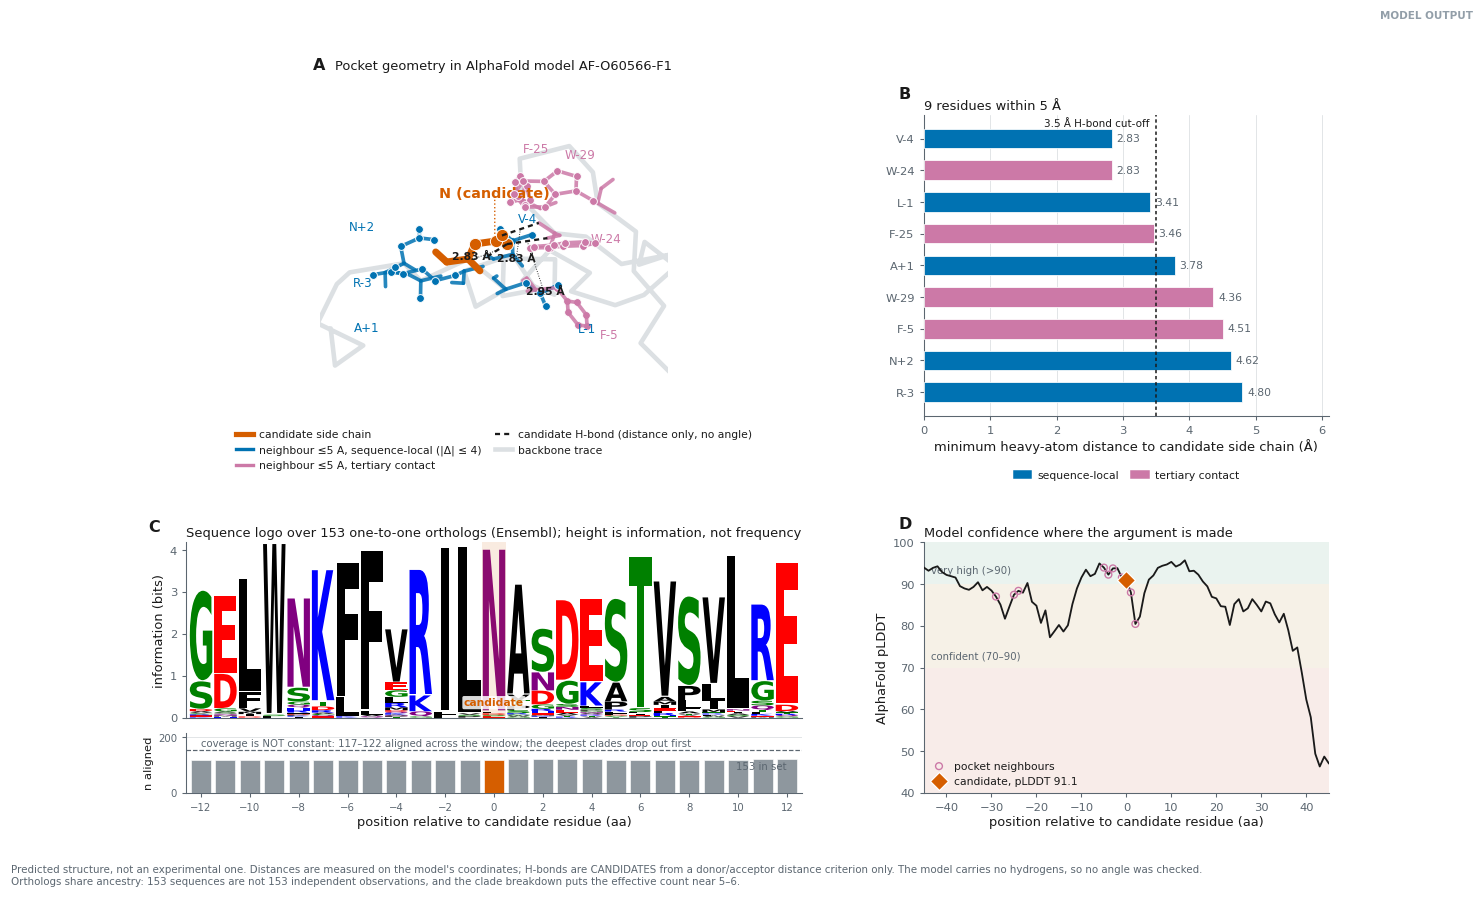

> **Figura principal 1 · geometria del bolsillo y restriccion evolutiva**  
> `EXP-010 · EXP-011` · figure class `MODEL_OUTPUT`, figura cientifica · evidence origin `PREDICTED+EXTERNAL`  
> *Lectura.* geometria local, confianza del modelo y restriccion evolutiva en la misma figura. 9 residuos con algun atomo pesado a 5 A o menos, de los cuales 4 son contactos TERCIARIOS; 3 puentes de hidrogeno CANDIDATOS desde la cadena lateral, el mas corto a 2.83 A; pLDDT 91.1 en el candidato; y una columna de alineamiento con 4.04 bits de 4.32 sobre 153 ortologos, con la cobertura del alineamiento a la vista porque NO es constante.  
> **Lo que no se puede concluir.** que la sustitucion desestabilice la proteina. Describe el entorno del residuo SILVESTRE; no hay calculo de energia libre, y sin hidrogenos en el modelo los puentes de H son candidatos geometricos, no confirmados. Los ortologos comparten ancestro: no son observaciones independientes, y el desglose por clado deja el numero efectivo en ~5-6.  
> datos: `work/struct/AF-O60566-F1.pdb + work/conservation/orthologs.json` · libreria: `matplotlib 3D + logomaker + src/structure/pocket_geometry.py` · procedencia: `figures/pub/fig03_pocket_and_conservation.svg + .png 300 dpi`

In [5]:
from src.figures import fig03_pocket as FP

LOGO = FP.prepare_logo(TGT)
fig = FP.build(S, LOGO)
fl.pub(fig, "Figura principal 1 · geometria del bolsillo y restriccion evolutiva",
       "EXP-010 · EXP-011", "PREDICTED+EXTERNAL", "MODEL_OUTPUT",
       f"geometria local, confianza del modelo y restriccion evolutiva en la misma figura. "
       f"{len(NB)} residuos con algun atomo pesado a {pg.CONTACT:.0f} A o menos, de los "
       f"cuales {sum(1 for x in NB if not x['contiguo'])} son contactos TERCIARIOS; "
       f"{len(sc)} puentes de hidrogeno CANDIDATOS desde la cadena lateral, el mas corto a "
       f"{min((h['dist'] for h in sc), default=float('nan')):.2f} A; pLDDT {S['plddt']:.1f} "
       f"en el candidato; y una columna de alineamiento con "
       f"{LOGO['info_at_candidate']:.2f} bits de {LOGO['hmax']:.2f} sobre "
       f"{LOGO['n_orthologs']} ortologos, con la cobertura del alineamiento a la vista "
       f"porque NO es constante.",
       "que la sustitucion desestabilice la proteina. Describe el entorno del residuo "
       "SILVESTRE; no hay calculo de energia libre, y sin hidrogenos en el modelo los "
       "puentes de H son candidatos geometricos, no confirmados. Los ortologos comparten "
       "ancestro: no son observaciones independientes, y el desglose por clado deja el "
       "numero efectivo en ~5-6.",
       source="work/struct/AF-O60566-F1.pdb + work/conservation/orthologs.json",
       lib="matplotlib 3D + logomaker + src/structure/pocket_geometry.py",
       slug="fig03_pocket_and_conservation")

### Vista interactiva de la misma región, fuera del notebook, a propósito

`py3Dmol` sobre el **mismo fichero**. Pero **no se renderiza aquí**, y el motivo lo destapó el
escáner de saneado, no una revisión a ojo: el widget serializa dentro del `.ipynb` el PDB
completo y las llamadas `addStyle` / `zoomTo` con los **números de residuo absolutos**. Eso
metería el residuo candidato en un fichero versionado.

Así que la vista se genera igual, es reproducible igual, y se escribe en `work/`, ignorado por
git. La figura científica es la estática de arriba, que además es la que se ve en GitHub.

In [6]:
try:
    import py3Dmol
    v = py3Dmol.view(width=900, height=520)
    v.addModel(io.open("work/struct/AF-O60566-F1.pdb", encoding="utf-8").read(), "pdb")
    v.setStyle({"cartoon": {"colorscheme": {"prop": "b", "gradient": "roygb",
                                            "min": 50, "max": 100}}})
    for nbr in NB:
        v.addStyle({"resi": nbr["resnum"]}, {"stick": {"radius": 0.14, "color": "0x8C99A4"}})
    v.addStyle({"resi": TGT}, {"stick": {"radius": 0.26, "color": "0xC07A2E"}})
    v.zoomTo({"resi": [TGT] + [nbr["resnum"] for nbr in NB]})
    OUTV = "work/struct/pocket_view.html"
    io.open(OUTV, "w", encoding="utf-8").write(v.write_html())
    print(f"  vista interactiva escrita en {OUTV} ({os.path.getsize(OUTV)/1024:.0f} kB)")
    print("  cartoon coloreado por pLDDT (azul alto -> rojo bajo) · palos: bolsillo ·")
    print("  naranja: residuo candidato · abrir en un navegador para girarla")
    print()
    print("  NO se muestra inline: el widget incrustaria el PDB y los numeros de residuo")
    print("  absolutos en el .ipynb, que es un fichero versionado.")
except Exception as e:
    print("py3Dmol no disponible en este entorno:", type(e).__name__, e)

  vista interactiva escrita en work/struct/pocket_view.html (686 kB)
  cartoon coloreado por pLDDT (azul alto -> rojo bajo) · palos: bolsillo ·
  naranja: residuo candidato · abrir en un navegador para girarla

  NO se muestra inline: el widget incrustaria el PDB y los numeros de residuo
  absolutos en el .ipynb, que es un fichero versionado.


## Resultado primario 2 · el interrogatorio estructural

Y su **corrección a la baja**: la primera versión concluía «desestabilizante». El análisis
geométrico del mutante debilitó dos de los tres argumentos.

## Resultado primario 3 · conservación ortóloga

Un porcentaje de identidad suelto es ininterpretable. Hacen falta tres controles: **línea base
interna**, **cobertura comparable** y **desglose por clado**, porque 120 ortólogos no son 120
observaciones independientes.

In [7]:
c = json.load(io.open("work/conservation/conservation_full.json", encoding="utf-8"))
cand, cc = c["candidate"], c["coverage_comparable"]
print(f"  ortologos 1:1                       : {c['n_orthologs_one2one']}")
print(f"  identidad en la posicion candidata  : {cand['identity_pct']} %")
print(f"  mediana de toda la proteina         : {c['baseline']['median_identity_pct']} %")
print(f"  percentil (cobertura comparable)    : {cc['candidate_percentile']}")
print(f"  capacidad ACEPTORA conservada       : {cand['acceptor_pct']} %")
print()
print("  por clado:")
for r in c["by_clade"]:
    acc = f"{r['acceptor_pct']:.0f} %" if r["acceptor_pct"] is not None else "  —"
    print(f"    {r['clade']:<26} {r['n_aligned']:>3}/{r['n_species']:<3} alinean · aceptor {acc}")

  ortologos 1:1                       : 153
  identidad en la posicion candidata  : 96.67 %
  mediana de toda la proteina         : 74.78 %
  percentil (cobertura comparable)    : 92.7
  capacidad ACEPTORA conservada       : 99.2 %

  por clado:
    primates                    23/23  alinean · aceptor 100 %
    otros mamiferos             67/68  alinean · aceptor 100 %
    aves                        12/13  alinean · aceptor 92 %
    reptiles                    12/13  alinean · aceptor 100 %
    anfibios                     2/2   alinean · aceptor 100 %
    peces con aleta radiada      4/33  alinean · aceptor 100 %
    vertebrados basales          0/1   alinean · aceptor   —


### Figura principal 3 · logo de secuencia sobre el alineamiento ortólogo real

Un percentil es un número. Un **logo de secuencia** enseña la restricción residuo a residuo:
qué se ve realmente en cada columna del alineamiento y con qué frecuencia. Se construye sobre
los mismos ortólogos `one2one` de Ensembl, sin ningún alineamiento nuevo.

In [8]:
import logomaker
from src.structure.ortholog_conservation import _one2one, per_position

HOM = _one2one("work/conservation/orthologs.json")
human, aligned, ident, observed = per_position(HOM)
WIN = 12
cols = [p for p in range(TGT - WIN, TGT + WIN + 1) if p in observed]

AAS = sorted({a for p in cols for a in observed[p] if a.isalpha()})
M = np.zeros((len(cols), len(AAS)))
for i, p in enumerate(cols):
    n = sum(v for k, v in observed[p].items() if k.isalpha())
    for j, a in enumerate(AAS):
        M[i, j] = observed[p].get(a, 0) / n if n else 0.0

# Contenido de informacion en bits: escala estandar de un logo de secuencia.
BG = 1.0 / 20
Hmax = np.log2(20)
info = np.array([Hmax + sum(q * np.log2(q) for q in row if q > 0) for row in M])
IM = M * info[:, None]

import pandas as pd
df = pd.DataFrame(IM, index=[p - TGT for p in cols], columns=AAS)
print(f"  ortologos one2one usados            : {len(HOM)}")
print(f"  ventana                             : {min(df.index):+d} .. {max(df.index):+d} aa")
print(f"  ortologos alineados en el candidato : {aligned[TGT]}")
print(f"  informacion en el candidato         : {info[list(df.index).index(0)]:.2f} bits "
      f"de un maximo de {Hmax:.2f}")

  ortologos one2one usados            : 153
  ventana                             : -12 .. +12 aa
  ortologos alineados en el candidato : 120
  informacion en el candidato         : 4.04 bits de un maximo de 4.32


C:\Users\USUARIO\Downloads\mosaic-rescue\src\nb\figlib.py:116: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0.012, 1, 1))


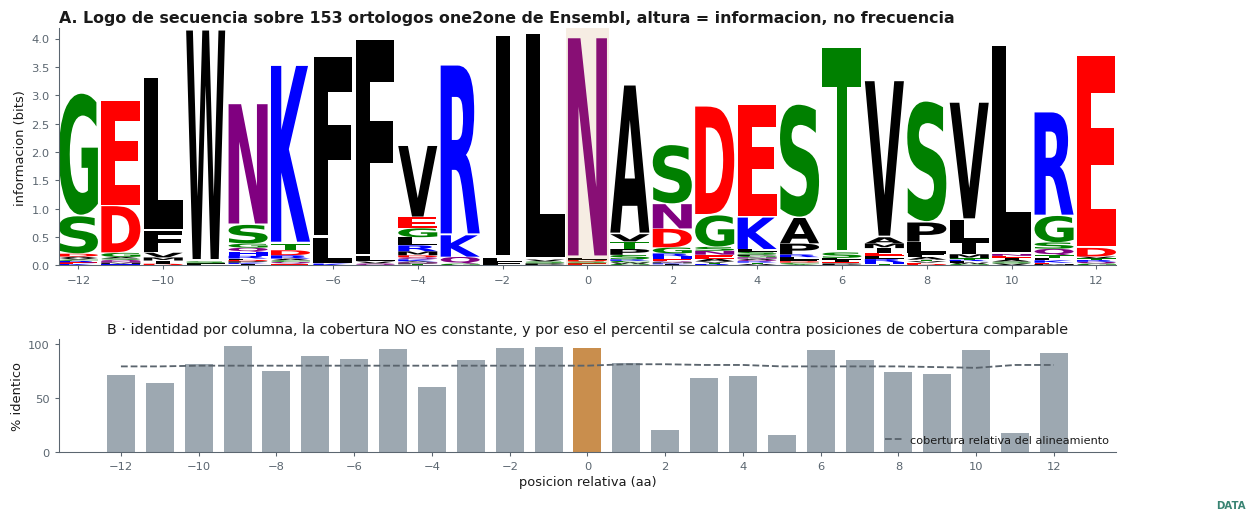

> **Figura principal 3 · logo de conservacion sobre el alineamiento ortologo**  
> `EXP-011` · figure class `DATA`, figura cientifica · evidence origin `EXTERNAL+DERIVED`  
> *Lectura.* la restriccion evolutiva columna a columna alrededor del candidato, sobre 153 ortologos one2one. La columna del candidato lleva 4.04 bits de 4.32 posibles y esta identica en 97 % de los 120 ortologos alineados ahi. El panel B enseña ademas por que hay que normalizar: la cobertura del alineamiento cambia de columna a columna dentro de la MISMA ventana.  
> **Lo que no se puede concluir.** que la conservacion sea independiente. Los ortologos comparten ancestro: 238 secuencias NO son 238 observaciones independientes, y el desglose por clado deja el numero efectivo en ~5-6. Tampoco dice nada sobre el efecto de la sustitucion: una posicion conservada puede tolerar el cambio concreto que tiene este caso.  
> datos: `work/conservation/orthologs.json · 153 ortologos one2one` · libreria: `logomaker`

In [9]:
fig, (axL, axK) = plt.subplots(2, 1, figsize=(12.4, 5.0),
                              gridspec_kw={"height_ratios": [2.1, 1], "hspace": 0.42})

logomaker.Logo(df, ax=axL, color_scheme="chemistry", vpad=0.02, width=0.92,
               font_name="DejaVu Sans")
axL.axvspan(-0.5, 0.5, color=fl.OPEN, alpha=0.13, lw=0, zorder=0)
axL.set_ylabel("informacion (bits)")
axL.set_xlabel("")
axL.set_xticks([p - TGT for p in cols][::2])
axL.set_title(f"A. Logo de secuencia sobre {len(HOM)} ortologos one2one de Ensembl, "
              f"altura = informacion, no frecuencia", fontsize=10.4, fontweight="bold",
              loc="left")
axL.grid(False)

# --- B · cobertura y conservacion de identidad, columna a columna -----------
xr = [p - TGT for p in cols]
idp = [100 * ident[p] / aligned[p] if aligned[p] else 0 for p in cols]
axK.bar(xr, idp, color=[fl.OPEN if p == TGT else fl.FLOW for p in cols], alpha=0.85, width=0.72)
axK.plot(xr, [aligned[p] / max(aligned.values()) * 100 for p in cols], color=fl.SOFT,
         lw=1.2, ls="--", label="cobertura relativa del alineamiento")
axK.set_ylim(0, 105); axK.set_xticks(xr[::2])
axK.set_ylabel("% identico"); axK.set_xlabel("posicion relativa (aa)")
axK.set_title("B · identidad por columna, la cobertura NO es constante, y por eso el "
              "percentil se calcula contra posiciones de cobertura comparable", fontsize=9.4)
axK.legend(fontsize=7.4, frameon=False, loc="lower right")

i0 = list(df.index).index(0)
fl.done(fig, "Figura principal 3 · logo de conservacion sobre el alineamiento ortologo",
        "EXP-011", "EXTERNAL+DERIVED", "DATA",
        f"la restriccion evolutiva columna a columna alrededor del candidato, sobre "
        f"{len(HOM)} ortologos one2one. La columna del candidato lleva "
        f"{info[i0]:.2f} bits de {Hmax:.2f} posibles y esta identica en "
        f"{100*ident[TGT]/aligned[TGT]:.0f} % de los {aligned[TGT]} ortologos alineados ahi. "
        f"El panel B enseña ademas por que hay que normalizar: la cobertura del alineamiento "
        f"cambia de columna a columna dentro de la MISMA ventana.",
        "que la conservacion sea independiente. Los ortologos comparten ancestro: 238 "
        "secuencias NO son 238 observaciones independientes, y el desglose por clado deja el "
        "numero efectivo en ~5-6. Tampoco dice nada sobre el efecto de la sustitucion: una "
        "posicion conservada puede tolerar el cambio concreto que tiene este caso.",
        source="work/conservation/orthologs.json · " + str(len(HOM)) + " ortologos one2one",
        lib="logomaker")

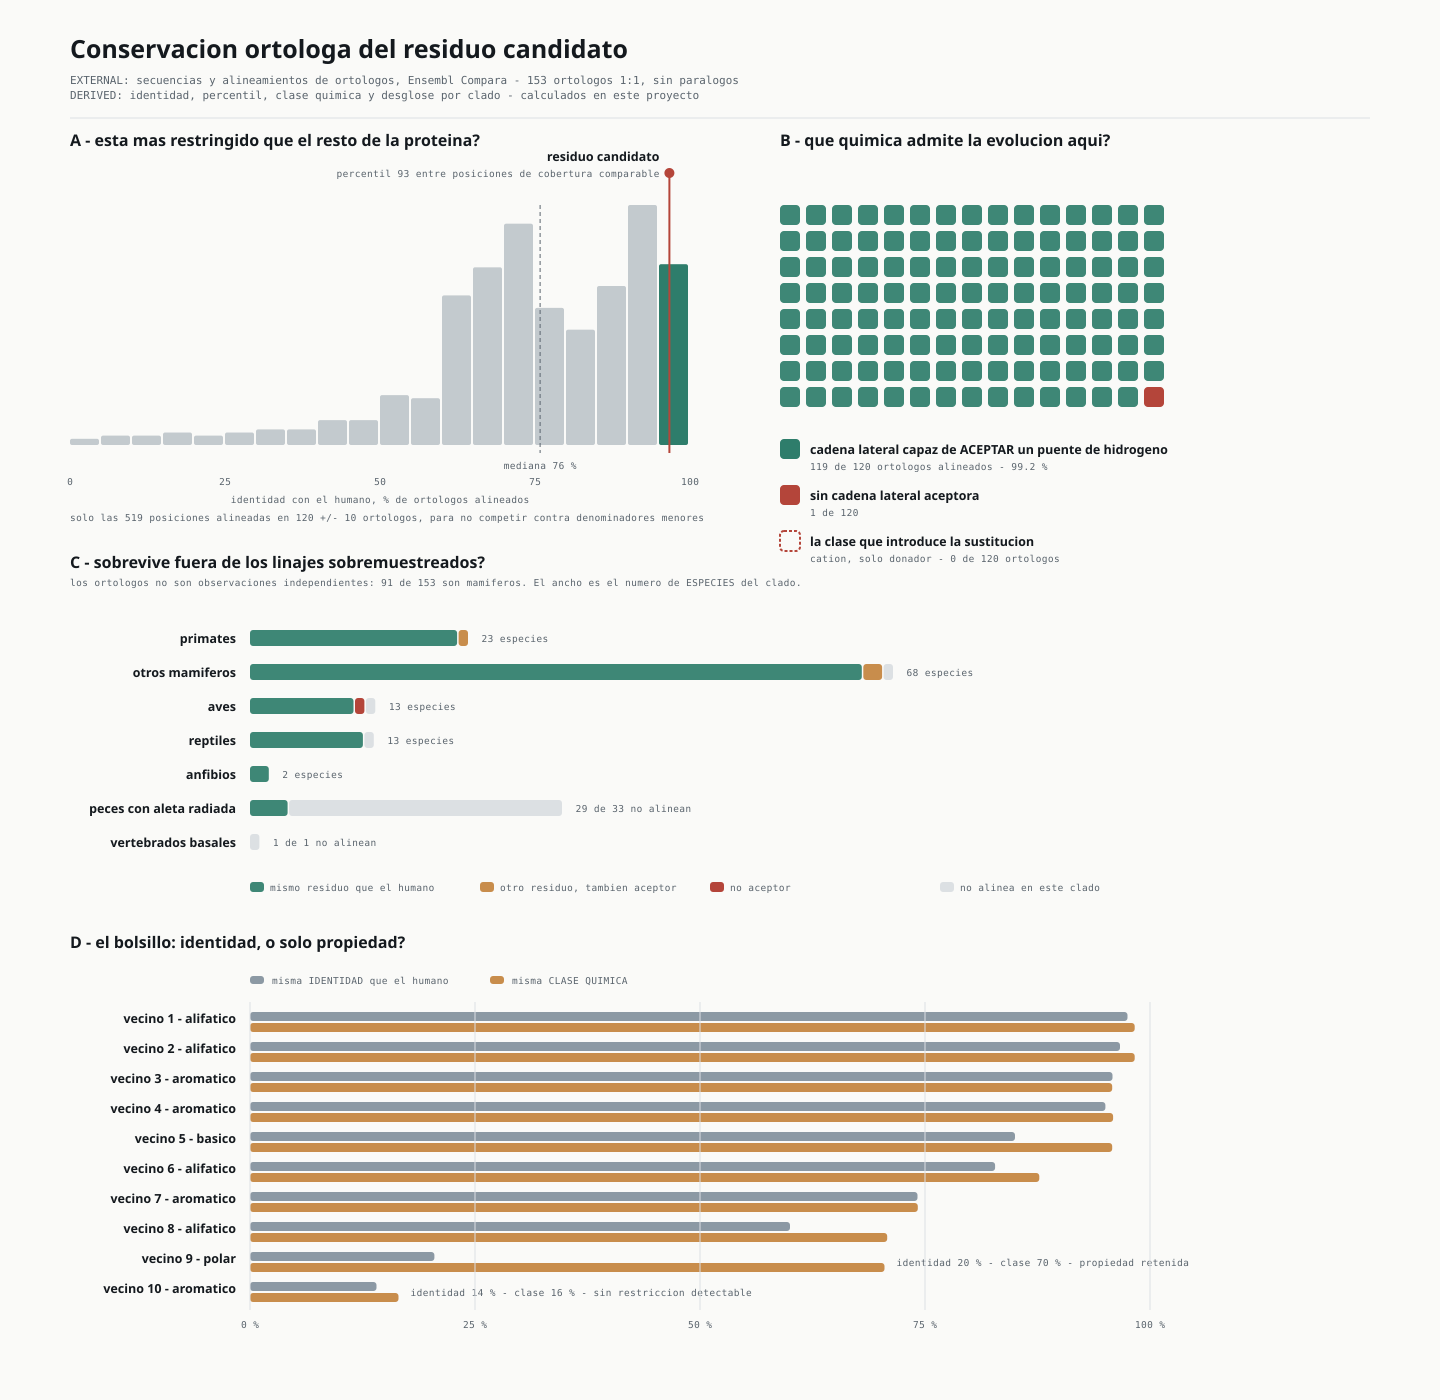

> **Figura principal 4 · conservacion ortologa con sus tres controles**  
> `EXP-011` · figure class `DATA`, figura cientifica · evidence origin `EXTERNAL+DERIVED`  
> *Lectura.* la posicion esta en el percentil 92.7 de su PROPIA proteina entre posiciones de cobertura comparable. La restriccion es quimica antes que de identidad: 99.2 % de los ortologos alineados conservan una cadena capaz de ACEPTAR un puente de hidrogeno, y la clase cationica que introduce la sustitucion no aparece en NINGUNO.  
> **Lo que no se puede concluir.** conservacion en todos los vertebrados: en peces solo alinean 4 de 33 y en basales ninguno. Las observaciones efectivamente independientes son ~5-6 a nivel de clado, no 120. Y NO reabre PP3.  
> libreria: `SVG` · procedencia: `src/make_fig7.py genera fig7_conservation.svg, sha256[:12]=dda1c58d707b`

In [10]:
fl.svg("figures/fig7_conservation.svg",
       "Figura principal 4 · conservacion ortologa con sus tres controles",
       "EXP-011", "EXTERNAL+DERIVED", "DATA",
       f"la posicion esta en el percentil {cc['candidate_percentile']} de su PROPIA proteina "
       f"entre posiciones de cobertura comparable. La restriccion es quimica antes que de "
       f"identidad: {cand['acceptor_pct']} % de los ortologos alineados conservan una cadena "
       "capaz de ACEPTAR un puente de hidrogeno, y la clase cationica que introduce la "
       "sustitucion no aparece en NINGUNO.",
       "conservacion en todos los vertebrados: en peces solo alinean 4 de 33 y en basales "
       "ninguno. Las observaciones efectivamente independientes son ~5-6 a nivel de clado, "
       "no 120. Y NO reabre PP3.",
       generator="src/make_fig7.py")

### La sorpresa: esto falsó una explicación del propio proyecto

`docs/STRUCTURAL_MISSENSE.md` justificaba la discrepancia con REVEL diciendo que *«un residuo
puede ser estructuralmente crítico y aun así no estar profundamente conservado»*.

**Está conservado.** La explicación queda falsada, se conservó el texto original con la
anotación, y **la discrepancia con REVEL queda sin explicar y es más llamativa que antes**.

## Robustez · qué movería el missense, y qué no

El missense no se mueve por más predictores. Solo por dos cosas.

## Decisión

| | |
|---|---|
| **Estructura** | Residuo enterrado en región de alta confianza; pérdida rotámero-independiente de un puente aceptor. **Estructuralmente preocupante** |
| **Conservación** | **SURVIVES**, percentil 93, restricción química al 99,2 %, clase entrante en 0 de 120 |
| **Clasificación** | **Sin cambios: VUS** |
| **Efecto en ACMG** | **Ninguno** |

**La formulación defendible:** *structurally concerning and evolutionarily constrained;
destabilization has not been demonstrated.*

### Qué NO demuestra

No demuestra desestabilización · no restaura `PP3` · no establece patogenicidad · el bolsillo
es hidrofóbico conservado pero **la «jaula de cuatro aromáticos» no lo está**, uno de los
cuatro no se conserva ni en identidad ni en clase.

### Falsificador

Un ΔΔG explícito próximo a cero con repeticiones convergentes; o un ortólogo funcional con
catión en esa posición.

### Siguiente experimento

**Ensayo de abundancia y recambio de BUBR1 específico de variante** (`EXP-011b`). Es lo único
que resuelve la incertidumbre que ni la secuencia ni la estructura estática pueden tocar. **No
lo ejecuta este proyecto**; se registra porque cada rama debe terminar diciendo qué experimento
reduciría más la incertidumbre.